# Lab 22.3: Numbers People Can Read

Chapter 22 of *Explainable AI in Practice*. Two parts, both on synthetic data with fixed seeds:

1. **Natural frequencies for an alert.** The same deterioration alert (sensitivity 80 percent, specificity 90 percent) on wards with different prevalence, drawn as icon arrays.
2. **A delay forecast three ways.** A forecast of a passenger's arrival delay from similar past flights (nearest neighbors in scikit-learn), shown as a point, an interval and a quantile dotplot, then turned into a message.

Run-only: nothing needs to be written, only cells run and outputs read.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

def frequencies(n, prevalence, sensitivity, specificity):
    sick = round(n * prevalence)
    tp = round(sick * sensitivity)
    fp = round((n - sick) * (1 - specificity))
    return dict(prevalence=prevalence, deteriorate=sick, true_alerts=tp, missed=sick - tp,
                false_alarms=fp, alerts=tp + fp, ppv=round(tp / (tp + fp), 3))

table = pd.DataFrame([frequencies(1000, p, 0.80, 0.90) for p in (0.02, 0.05, 0.10, 0.20)])
table

,prevalence,deteriorate,true_alerts,missed,false_alarms,alerts,ppv
0,0.02,20,16,4,98,114,0.140
1,0.05,50,40,10,95,135,0.296
2,0.10,100,80,20,90,170,0.471
3,0.20,200,160,40,80,240,0.667


**Checkpoint 1.** At 5 percent prevalence: 135 alerts, 40 real, PPV 0.296. At 20 percent: 240 alerts, 160 real, PPV 0.667. At 2 percent the PPV is about 0.14: roughly six false alarms for every real one.

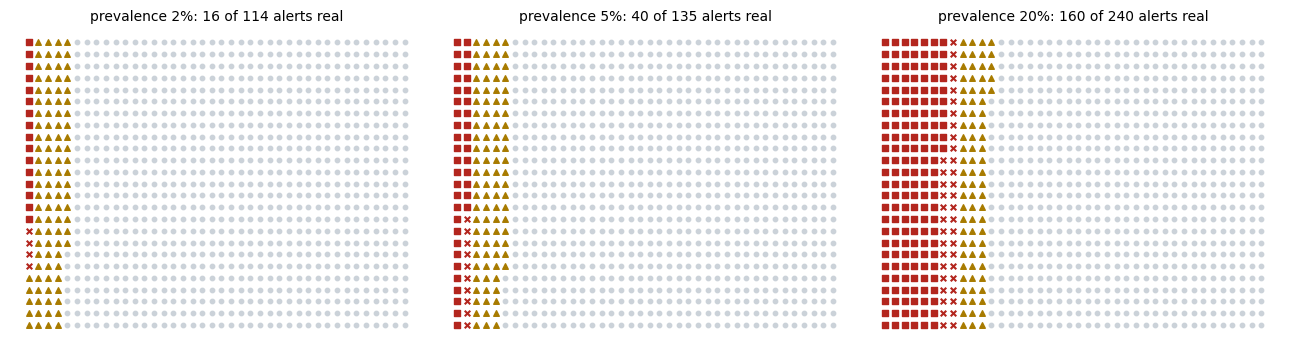

In [2]:
def icon_array(ax, n, prev, sens=0.80, spec=0.90):
    f = frequencies(n, prev, sens, spec)
    kinds = [0] * f["true_alerts"] + [1] * f["missed"] + [2] * f["false_alarms"]
    kinds += [3] * (n - len(kinds))
    kinds = np.array(kinds)
    rows, cols = 25, 40
    x = np.repeat(np.arange(cols), rows)
    y = np.tile(np.arange(rows)[::-1], cols)
    style = {0: ("s", "#B3261E"), 1: ("x", "#B3261E"), 2: ("^", "#A87B00"), 3: ("o", "#CBD2D9")}
    for k, (m, c) in style.items():
        idx = kinds == k
        ax.scatter(x[idx], y[idx], marker=m, c=c, s=10 if k == 3 else 16)
    ax.set_title(f"prevalence {prev:.0%}: {f['true_alerts']} of {f['alerts']} alerts real", fontsize=10)
    ax.axis("off")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, p in zip(axs, (0.02, 0.05, 0.20)):
    icon_array(ax, 1000, p)
plt.tight_layout(); plt.show()

Squares: deteriorate, alerted. Crosses: deteriorate, missed. Triangles: false alarms. Dots: stable, quiet. Shapes, not only colors, carry the meaning.

## Part 2: a delay forecast

A synthetic history of 5,000 flights: the delay of the inbound aircraft, the departure hour and the arrival delay. The passenger's flight has an inbound aircraft 25 minutes late and departs at 18:00. Her connection leaves 45 minutes after scheduled arrival and needs 20 minutes to transfer, so she has 25 minutes of slack.

In [3]:
rng = np.random.default_rng(22)
m = 5000
inbound = rng.gamma(1.3, 14, m)
hour = rng.integers(6, 23, m)
noise = rng.gamma(2.0, 6, m) - 12
arrival = 0.8 * inbound + 0.9 * np.maximum(hour - 15, 0) + noise
X = np.column_stack([inbound / 10, hour / 3])          # scaled so both features count
nn = NearestNeighbors(n_neighbors=200).fit(X)
_, idx = nn.kneighbors([[25 / 10, 18 / 3]])
pred = arrival[idx[0]]
slack = 25
q20 = np.quantile(pred, (np.arange(20) + 0.5) / 20)
print(f"median {np.median(pred):.1f} min, 80% interval {np.quantile(pred, 0.1):.1f} to {np.quantile(pred, 0.9):.1f}")
print(f"share of similar flights past the slack: {(pred > slack).mean():.3f}; dots past the line: {(q20 > slack).sum()} of 20")

median 19.8 min, 80% interval 12.2 to 32.6
share of similar flights past the slack: 0.265; dots past the line: 5 of 20


**Checkpoint 2.** Median about 20 minutes, 80 percent interval about 12 to 33 minutes, about 26 percent of similar flights past the slack, 5 of 20 dots past the line. (The figure script of the chapter uses the same data with a distance computed by hand; the numbers agree.)

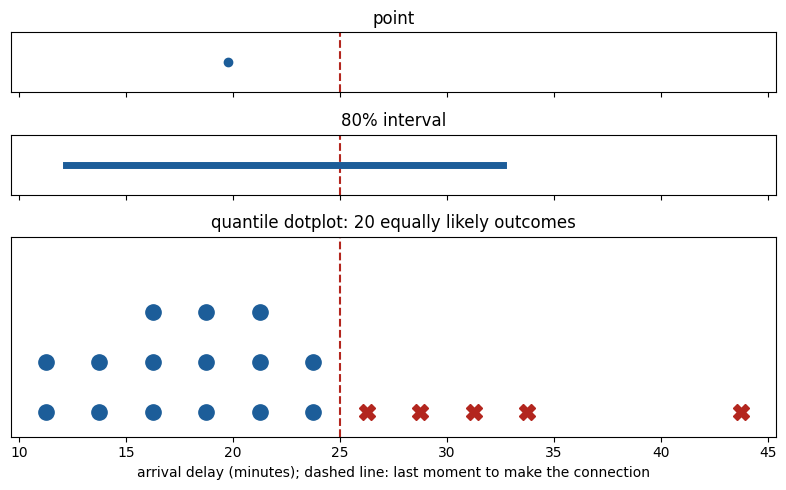

In [4]:
fig, axs = plt.subplots(3, 1, figsize=(8, 5), sharex=True, gridspec_kw=dict(height_ratios=[0.6, 0.6, 2]))
for a in axs:
    a.axvline(slack, color="#B3261E", ls="--"); a.set_yticks([])
axs[0].plot(np.median(pred), 0, "o", color="#1C5D99"); axs[0].set_title("point")
axs[1].plot(np.quantile(pred, [0.1, 0.9]), [0, 0], color="#1C5D99", lw=5); axs[1].set_title("80% interval")
w = 2.5
bins = np.floor((q20 - slack) / w) * w + slack + w / 2
counts = {}
for b, v in zip(bins, q20):
    k = counts.get(b, 0)
    axs[2].plot(b, k + 0.5, "X" if v > slack else "o", ms=11, color="#B3261E" if v > slack else "#1C5D99")
    counts[b] = k + 1
axs[2].set_ylim(0, max(counts.values()) + 1); axs[2].set_title("quantile dotplot: 20 equally likely outcomes")
axs[2].set_xlabel("arrival delay (minutes); dashed line: last moment to make the connection")
plt.tight_layout(); plt.show()

## Your messages

Write one sentence a passenger would receive for each display, for example:

- Point: "Your flight is expected to arrive 20 minutes late." (What will she do with this?)
- Interval: "Your flight will most likely arrive 12 to 33 minutes late."
- Dotplot: "In about 1 of 4 similar cases, flights like yours arrived too late for your connection. You can rebook now at no cost, or keep your connection."

Then change the inbound delay to 10 and to 40 minutes in the cell above, rerun, and rewrite the dotplot message. Note the inbound delay at which you would advise rebooking, and why.